# Feature redundancy
Area and Convex_Area show very similar distributions, as observed from their boxplots and descriptive statistics. The scatter plot also shows an extremely strong linear relationship between the two features, which is supported by their correlation coefficient of approximately 1.00. Both features exhibit similar class patterns. Therefore, Area and Convex_Area contain highly similar information and may be redundant. To reduce potential redundancy in Decision tree, we will evaluate a reduced feature set by removing one of these features and compare its performance with the model using both features.

In [74]:
features_set1 = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
features_set2 = ['Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
features_set3 = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Extent']

In [75]:
import pandas as pd

train_set1 = pd.read_csv("train_set1.csv")

X_train_set1 = train_set1.drop(columns=["Target"])
y_train_set1 = train_set1["Target"]

train_set2 = pd.read_csv("train_set2.csv")

X_train_set2 = train_set2.drop(columns=["Target"])
y_train_set2 = train_set2["Target"]

train_set3 = pd.read_csv("train_set3.csv")

X_train_set3 = train_set3.drop(columns=["Target"])
y_train_set3 = train_set3["Target"]

# Train the model without Convex_Area (set3)

# Train base model

In [76]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
import numpy as np

# Baseline model
decision_tree_model_set3 = DecisionTreeClassifier(random_state=42)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    decision_tree_model_set3,
    X_train_set3,
    y_train_set3,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

## Evaluate model

In [77]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [1. 1. 1. 1. 1.]
Validation accuracy: [0.87540984 0.89180328 0.89180328 0.87356322 0.8998358 ]
Mean training accuracy: 1.0
Mean validation accuracy: 0.8864830816441897
Validation accuracy std: 0.010241519597485241
Mean F1: 0.8839858393734407
Mean Precision: 0.8843759912403355
Mean Recall: 0.8837731483240822


## Hyperparameter tuning

In [78]:
from sklearn.model_selection import GridSearchCV

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 3, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

decision_tree_model_set3_tuned = DecisionTreeClassifier(
    random_state=42
)

grid_search_dt_set3 = GridSearchCV(
    estimator=decision_tree_model_set3_tuned,
    param_grid=param_grid_dt,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

grid_search_dt_set3.fit(X_train_set3, y_train_set3)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [None, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': 'f1_macro', 'precision': 'precision_macro', 'recall': 'recall_macro'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that ca

In [79]:
results = pd.DataFrame(grid_search_dt_set3.cv_results_)
best_results = results.loc[grid_search_dt_set3.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_dt_set3.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Mean Train Accuracy:      0.9327
Mean CV Accuracy:         0.9272
Mean CV Precision:        0.9267
Mean CV Recall:           0.9257
Mean CV F1-Score:         0.9256
Train-CV Accuracy Gap:    0.0055
No strong overfitting signal based on this accuracy gap.


In [80]:
# Obtain best model

best_decision_tree_set3 = grid_search_dt_set3.best_estimator_

y_pred_dt_set3_tuned = best_decision_tree_set3.predict(X_test_set3)

# Train the model without Area (set2)

# Train base model

In [81]:
# Baseline model
decision_tree_model_set2 = DecisionTreeClassifier(random_state=42)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    decision_tree_model_set2,
    X_train_set2,
    y_train_set2,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

## Evaluate model

In [82]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [1. 1. 1. 1. 1.]
Validation accuracy: [0.86885246 0.88688525 0.89016393 0.88013136 0.89819376]
Mean training accuracy: 1.0
Mean validation accuracy: 0.8848453524993942
Validation accuracy std: 0.009885573413994698
Mean F1: 0.8824595031418557
Mean Precision: 0.8825740218686866
Mean Recall: 0.8826437457195289


## Hyperparameter tuning

In [83]:
scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

decision_tree_model_set2_tuned = DecisionTreeClassifier(
    random_state=42
)

param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 3, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

grid_search_dt_set2 = GridSearchCV(
    estimator=decision_tree_model_set2_tuned,
    param_grid=param_grid_dt,
    scoring=scoring_metrics,
    cv=5,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

grid_search_dt_set2.fit(X_train_set2, y_train_set2)

print("Best Parameters:", grid_search_dt_set2.best_params_)
print("Best CV Accuracy:", grid_search_dt_set2.best_score_)

Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10}
Best CV Accuracy: 0.9284793668739401


In [84]:
results = pd.DataFrame(grid_search_dt_set2.cv_results_)
best_results = results.loc[grid_search_dt_set2.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_dt_set2.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10}
Mean Train Accuracy:      0.9398
Mean CV Accuracy:         0.9285
Mean CV Precision:        0.9270
Mean CV Recall:           0.9275
Mean CV F1-Score:         0.9270
Train-CV Accuracy Gap:    0.0113
No strong overfitting signal based on this accuracy gap.


In [85]:
# Obtain best model

best_decision_tree_set2_tuned = grid_search_dt_set2.best_estimator_

# Train the model using all features (set1)

# Train base model

In [86]:
# Baseline model
decision_tree_model = DecisionTreeClassifier(random_state=42)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    decision_tree_model,
    X_train_set1,
    y_train_set1,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

## Evaluate model

In [87]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [1. 1. 1. 1. 1.]
Validation accuracy: [0.88360656 0.88688525 0.89672131 0.87192118 0.89490969]
Mean training accuracy: 1.0
Mean validation accuracy: 0.8868087970066488
Validation accuracy std: 0.008897006619498476
Mean F1: 0.884397097834
Mean Precision: 0.8844471120766535
Mean Recall: 0.8844472439043134


## Hyperparameter tuning

In [88]:
from sklearn.model_selection import GridSearchCV

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 3, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

grid_search_dt = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=param_grid_dt,
    scoring=scoring_metrics,
    cv=5,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

grid_search_dt.fit(X_train_set1, y_train_set1)

print("Best Parameters:", grid_search_dt.best_params_)
print("Best CV Accuracy:", grid_search_dt.best_score_)

Best Parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV Accuracy: 0.9271662763466043


In [89]:
results = pd.DataFrame(grid_search_dt.cv_results_)
best_results = results.loc[grid_search_dt.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_dt.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Mean Train Accuracy:      0.9327
Mean CV Accuracy:         0.9272
Mean CV Precision:        0.9267
Mean CV Recall:           0.9257
Mean CV F1-Score:         0.9256
Train-CV Accuracy Gap:    0.0055
No strong overfitting signal based on this accuracy gap.


# Evaluate models removing outliers

## Outlier distribution of training and testing set
(Model without redundant feature 'Area')

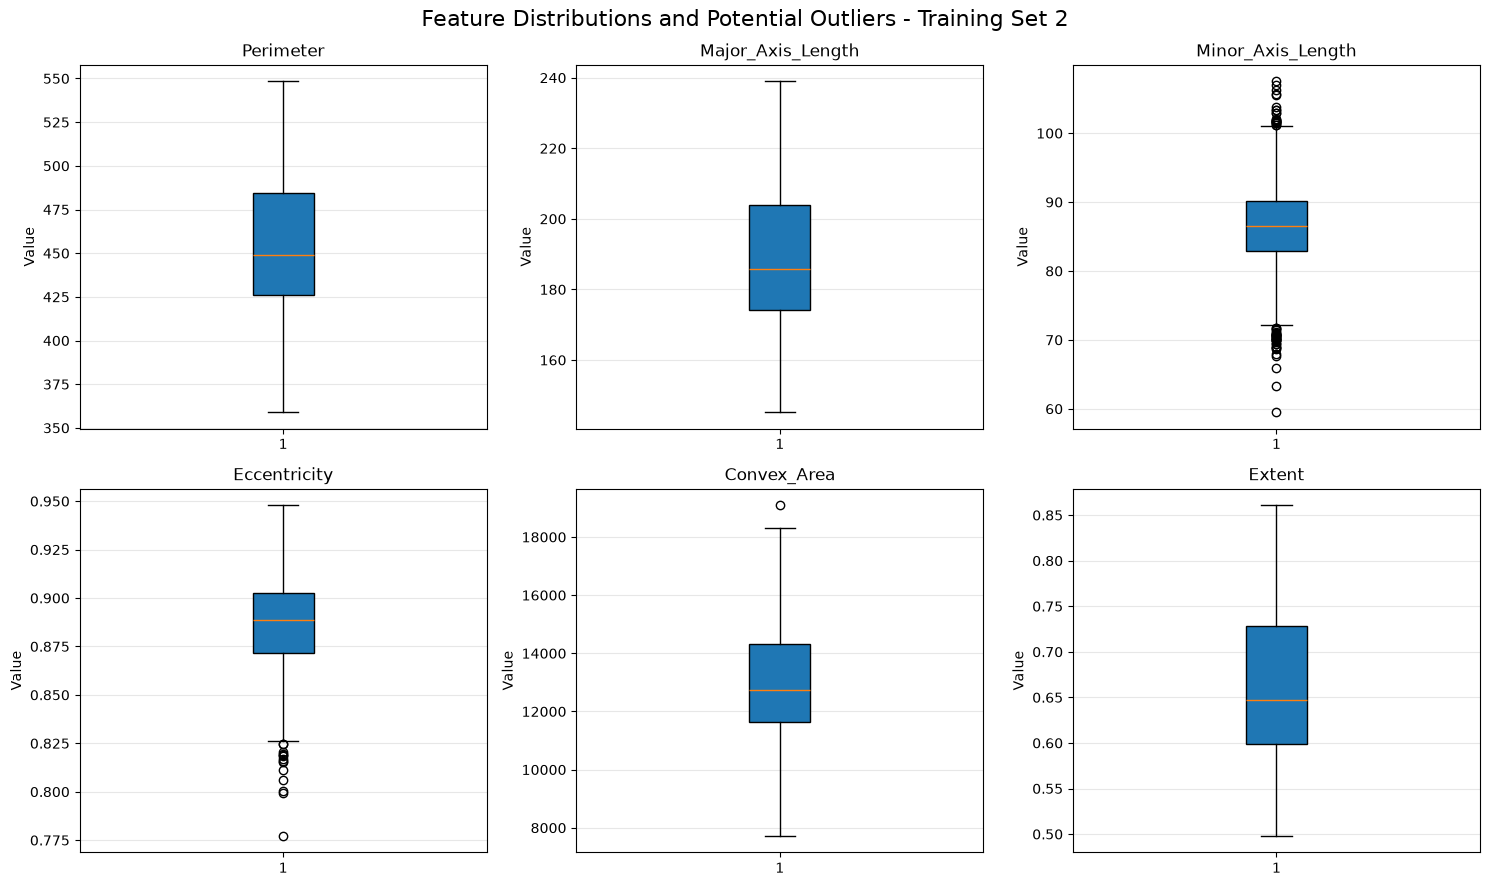

In [90]:
import matplotlib.pyplot as plt

features_set2 = X_train_set2.columns

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, feature in enumerate(features_set2):
    axes[i].boxplot(
        X_train_set2[feature],
        patch_artist=True
    )
    
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Feature Distributions and Potential Outliers - Training Set 2",
    fontsize=16
)

plt.tight_layout()
plt.show()

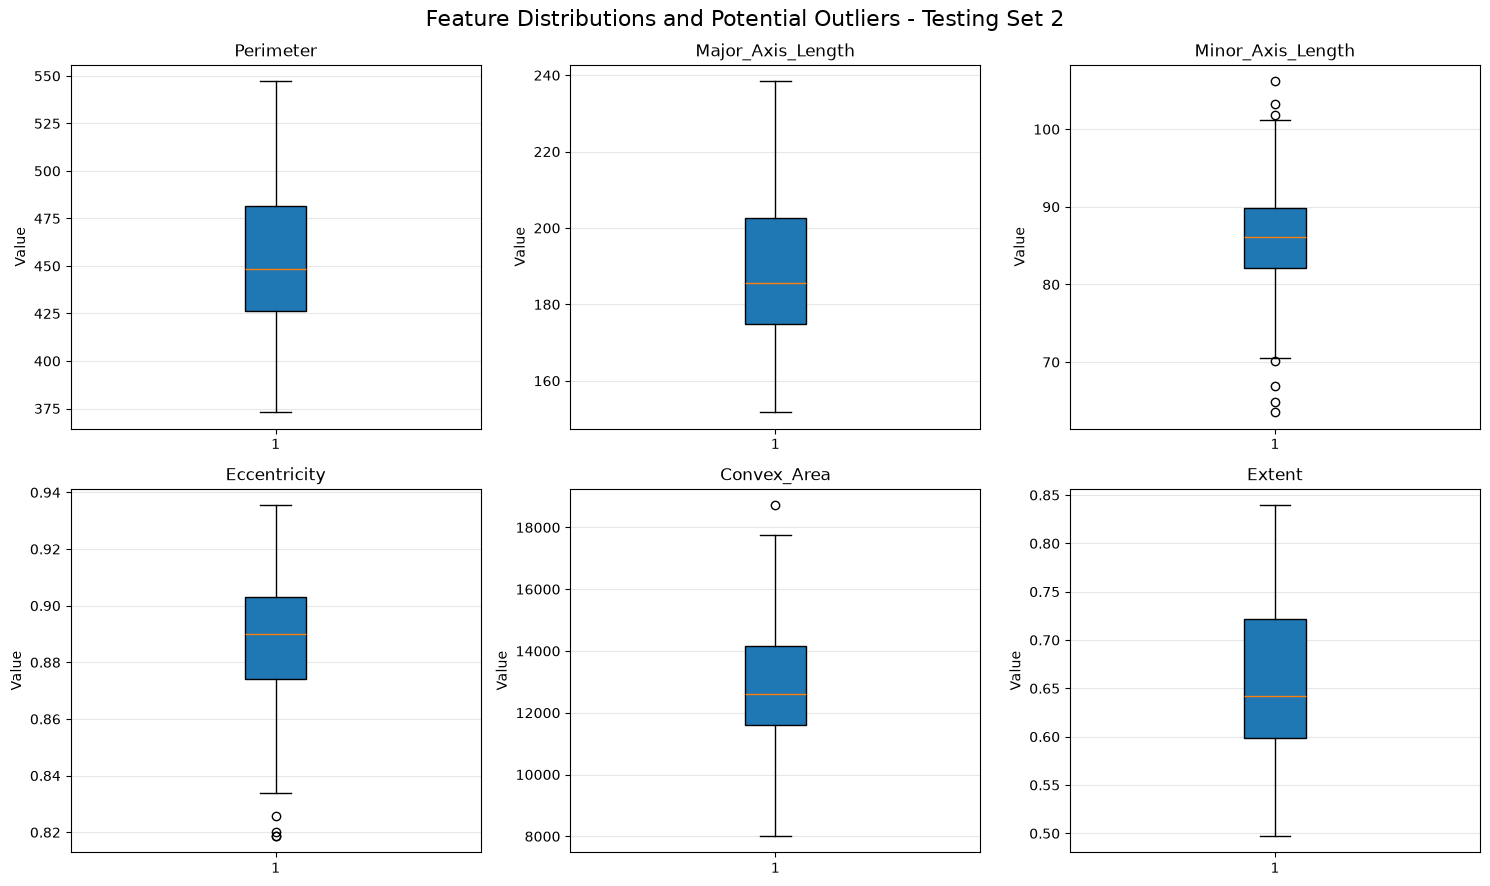

In [91]:
import matplotlib.pyplot as plt

features_set2 = X_test_set2.columns

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, feature in enumerate(features_set2):
    axes[i].boxplot(
        X_test_set2[feature],
        patch_artist=True
    )
    
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Feature Distributions and Potential Outliers - Testing Set 2",
    fontsize=16
)

plt.tight_layout()
plt.show()

In training set, Minor_Axis_Length, Eccentricity and Convex area has outliers.

In [92]:
# Remove outliers
import pandas as pd

outlier_features = [
    "Minor_Axis_Length",
    "Eccentricity",
    "Convex_Area"
]

X_train_set2_clean = X_train_set2.copy()
y_train_set2_clean = y_train_set2.copy()

for feature in outlier_features:

    Q1 = X_train_set2_clean[feature].quantile(0.25)
    Q3 = X_train_set2_clean[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask = (
        (X_train_set2_clean[feature] >= lower_bound) &
        (X_train_set2_clean[feature] <= upper_bound)
    )

    X_train_set2_clean = X_train_set2_clean[mask]
    y_train_set2_clean = y_train_set2_clean.loc[X_train_set2_clean.index]

    print(f"{feature}")
    print(f"Lower bound: {lower_bound:.4f}")
    print(f"Upper bound: {upper_bound:.4f}")
    print(f"Remaining rows: {len(X_train_set2_clean)}")
    print()

Minor_Axis_Length
Lower bound: 71.9833
Upper bound: 101.0960
Remaining rows: 2991

Eccentricity
Lower bound: 0.8261
Upper bound: 0.9477
Remaining rows: 2977

Convex_Area
Lower bound: 7690.0000
Upper bound: 18290.0000
Remaining rows: 2977



In [93]:
# Removed rows count
print("Original training rows:", len(X_train_set2))
print("Clean training rows:", len(X_train_set2_clean))
print("Rows removed:", len(X_train_set2) - len(X_train_set2_clean))

Original training rows: 3048
Clean training rows: 2977
Rows removed: 71


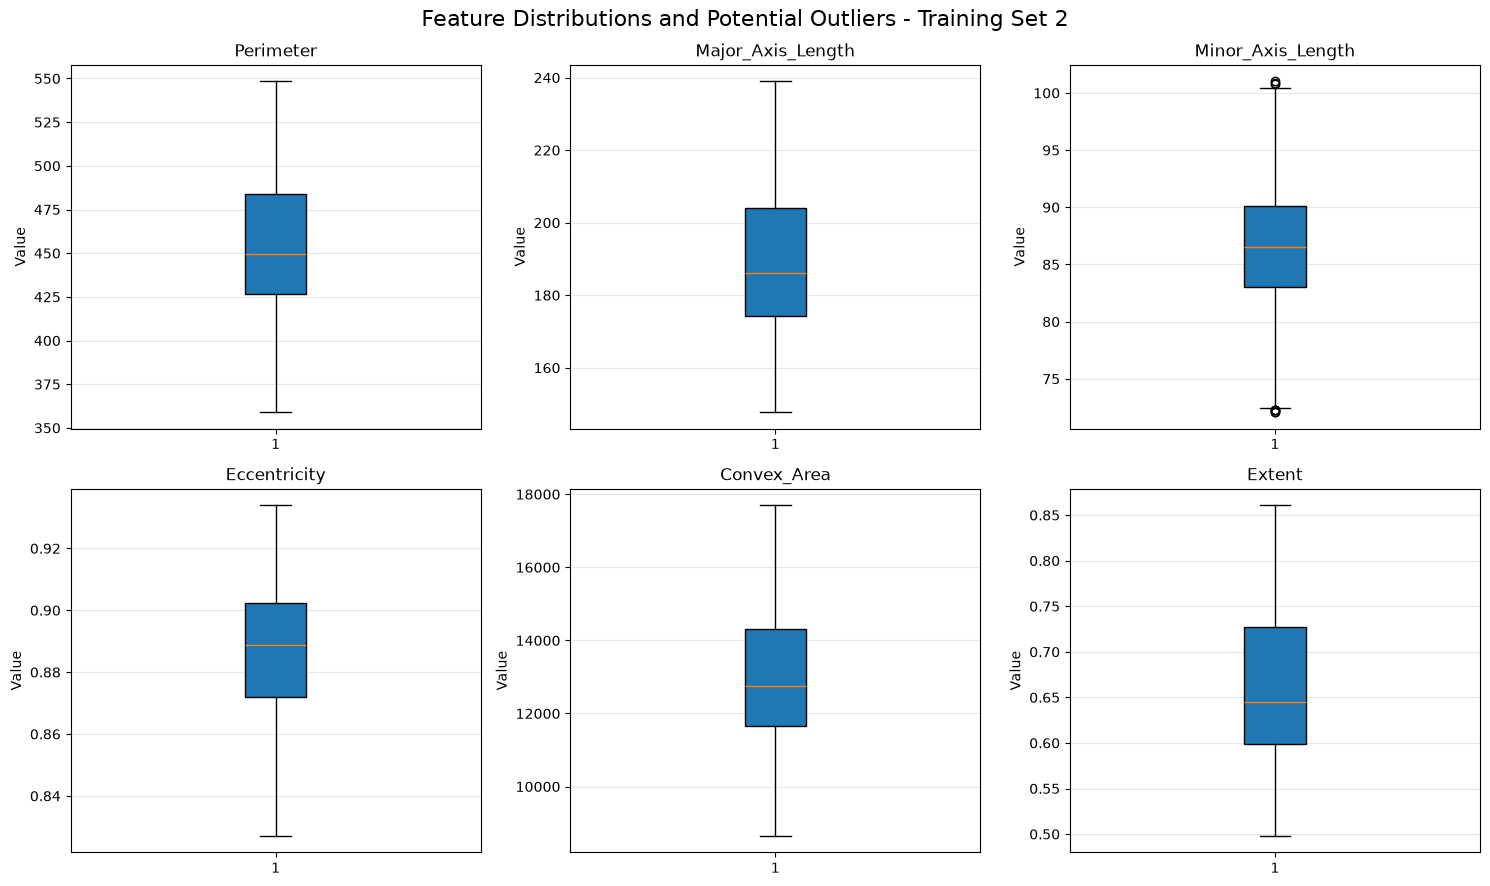

In [94]:
import matplotlib.pyplot as plt

features_set2 = X_train_set2_clean.columns

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, feature in enumerate(features_set2):
    axes[i].boxplot(
        X_train_set2_clean[feature],
        patch_artist=True
    )
    
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Feature Distributions and Potential Outliers - Training Set 2",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Train the model using cleaned training data

# Train the model without Area (set2)

# Train base model

In [95]:
decision_tree_model = DecisionTreeClassifier(random_state=42)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    decision_tree_model,
    X_train_set2_clean,
    y_train_set2_clean,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

## Evaluate model

In [96]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [1. 1. 1. 1. 1.]
Validation accuracy: [0.89261745 0.88926174 0.85882353 0.86218487 0.89915966]
Mean training accuracy: 1.0
Mean validation accuracy: 0.8804094523715527
Validation accuracy std: 0.016595517719206396
Mean F1: 0.8783790565784511
Mean Precision: 0.8777629755271119
Mean Recall: 0.8794613029347961


## Hyperparameter tuning

In [97]:
from sklearn.model_selection import GridSearchCV

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 3, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

grid_search_dt = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=param_grid_dt,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

grid_search_dt.fit(X_train_set2_clean, y_train_set2_clean)

print("Best Parameters:", grid_search_dt.best_params_)
print("Best CV Accuracy:", grid_search_dt.best_score_)

Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV Accuracy: 0.9260972308386443


In [98]:
results = pd.DataFrame(grid_search_dt.cv_results_)
best_results = results.loc[grid_search_dt.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_dt.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Mean Train Accuracy:      0.9398
Mean CV Accuracy:         0.9261
Mean CV Precision:        0.9246
Mean CV Recall:           0.9251
Mean CV F1-Score:         0.9247
Train-CV Accuracy Gap:    0.0137
No strong overfitting signal based on this accuracy gap.


# Check class imbalance

In [99]:
class_distribution = pd.DataFrame({
    "Count": y_train_set2.value_counts(),
    "Percentage": y_train_set2.value_counts(normalize=True) * 100
})

print(class_distribution)

          Count  Percentage
Target                     
Osmancik   1744   57.217848
Cammeo     1304   42.782152


### Balance the classes using SMOTE

In [100]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_set2_balanced, y_train_set2_balanced = smote.fit_resample(
    X_train_set2,
    y_train_set2
)

In [101]:
class_distribution_balanced = pd.DataFrame({
    "Count": y_train_set2_balanced.value_counts(),
    "Percentage": y_train_set2_balanced.value_counts(normalize=True) * 100
})

print(class_distribution_balanced)

          Count  Percentage
Target                     
Osmancik   1744        50.0
Cammeo     1744        50.0


### Train the final selected model

# Train base model

In [102]:
decision_tree_model = DecisionTreeClassifier(random_state=42)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    decision_tree_model,
    X_train_set2_balanced,
    y_train_set2_balanced,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

## Evaluate model

In [103]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [1. 1. 1. 1. 1.]
Validation accuracy: [0.90687679 0.91404011 0.89971347 0.86083214 0.89813486]
Mean training accuracy: 1.0
Mean validation accuracy: 0.8959194747855113
Validation accuracy std: 0.018432818066985053
Mean F1: 0.8959119821413977
Mean Precision: 0.8960200261243934
Mean Recall: 0.8959152587030268


## Hyperparameter tuning

In [104]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# Decision Tree + SMOTE pipeline
pipeline_dt_smote = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', DecisionTreeClassifier(random_state=42))
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# Hyperparameter grid
param_grid_dt = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [None, 3, 5, 10, 15, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 5]
}

# Grid Search with 5-fold CV
grid_search_dt_smote = GridSearchCV(
    estimator=pipeline_dt_smote,
    param_grid=param_grid_dt,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_dt_smote.fit(X_train_set2, y_train_set2)

# Results
print("Best Parameters:", grid_search_dt_smote.best_params_)
print("Best CV Accuracy:", grid_search_dt_smote.best_score_)

Best Parameters: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Best CV Accuracy: 0.9278193221890225


In [105]:
results = pd.DataFrame(grid_search_dt_smote.cv_results_)
best_results = results.loc[grid_search_dt_smote.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_dt_smote.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Mean Train Accuracy:      0.9314
Mean CV Accuracy:         0.9278
Mean CV Precision:        0.9252
Mean CV Recall:           0.9289
Mean CV F1-Score:         0.9266
Train-CV Accuracy Gap:    0.0036
No strong overfitting signal based on this accuracy gap.


# Forward Feature Selection

In [106]:
# Configure cross-validation
cv_ffs = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [107]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone
import pandas as pd


# Define evaluation metrics
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

# Implement Forward Feature Selection
selected_features = []
remaining_features = X_train_set2.columns.tolist()
ffs_results = []

while remaining_features:

    candidate_results = []

    for feature in remaining_features:

        candidate_features = selected_features + [feature]

        model = clone(best_decision_tree_set2_tuned)

        # Evaluate the candidate feature subset
        scores = cross_validate(
            model,
            X_train_set2[candidate_features],
            y_train_set2,
            cv=cv_ffs,
            scoring=scoring_metrics,
            return_train_score=True,
            n_jobs=-1
        )

        candidate_results.append({
            "Feature": feature,

            "Train Accuracy": scores["train_accuracy"].mean(),
            "Mean CV Accuracy": scores["test_accuracy"].mean(),
            "CV Std": scores["test_accuracy"].std(),

            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1-Score": scores["test_f1"].mean()
        })

    # Select the feature with the highest mean CV accuracy
    candidate_results.sort(
        key=lambda x: x["Mean CV Accuracy"],
        reverse=True
    )

    best_candidate = candidate_results[0]

    selected_features.append(best_candidate["Feature"])
    remaining_features.remove(best_candidate["Feature"])

    ffs_results.append({
        "Step": len(selected_features),
        "Added Feature": best_candidate["Feature"],
        "Selected Features": selected_features.copy(),
        "Number of Features": len(selected_features),

        "Train Accuracy": best_candidate["Train Accuracy"],
        "Mean CV Accuracy": best_candidate["Mean CV Accuracy"],
        "CV Std": best_candidate["CV Std"],

        "Precision": best_candidate["Precision"],
        "Recall": best_candidate["Recall"],
        "F1-Score": best_candidate["F1-Score"]
    })

# Create results DataFrame
ffs_df = pd.DataFrame(ffs_results)

# Display results as percentages
display(
    ffs_df.style.format({
        "Train Accuracy": "{:.2%}",
        "Mean CV Accuracy": "{:.2%}",
        "CV Std": "{:.4f}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}"
    })
)

,Step,Added Feature,Selected Features,Number of Features,Train Accuracy,Mean CV Accuracy,CV Std,Precision,Recall,F1-Score
0,1,Major_Axis_Length,['Major_Axis_Length'],1,93.54%,92.29%,0.0082,92.18%,92.14%,92.12%
1,2,Perimeter,"['Major_Axis_Length', 'Perimeter']",2,93.87%,92.75%,0.0110,92.58%,92.66%,92.60%
2,3,Eccentricity,"['Major_Axis_Length', 'Perimeter', 'Eccentricity']",3,93.98%,92.98%,0.0086,92.82%,92.87%,92.84%
3,4,Extent,"['Major_Axis_Length', 'Perimeter', 'Eccentricity', 'Extent']",4,93.94%,92.85%,0.0081,92.67%,92.75%,92.70%
4,5,Convex_Area,"['Major_Axis_Length', 'Perimeter', 'Eccentricity', 'Extent', 'Convex_Area']",5,93.86%,92.65%,0.0083,92.46%,92.59%,92.51%
5,6,Minor_Axis_Length,"['Major_Axis_Length', 'Perimeter', 'Eccentricity', 'Extent', 'Convex_Area', 'Minor_Axis_Length']",6,93.91%,92.45%,0.0082,92.25%,92.39%,92.31%


In [108]:
# Find the best feature subset based on CV accuracy
best_idx = ffs_df["Mean CV Accuracy"].idxmax()
best_row = ffs_df.loc[best_idx]

best_features_ffs = best_row["Selected Features"]

print("\nBest feature subset:", best_features_ffs)
print("Number of features:", len(best_features_ffs))
print(f"Train Accuracy: {best_row['Train Accuracy']:.4%}")
print(f"Mean CV Accuracy: {best_row['Mean CV Accuracy']:.4%}")
print(f"CV Standard Deviation: {best_row['CV Std']:.4f}")
print(f"Precision: {best_row['Precision']:.4%}")
print(f"Recall: {best_row['Recall']:.4%}")
print(f"F1-Score: {best_row['F1-Score']:.4%}")


Best feature subset: ['Major_Axis_Length', 'Perimeter', 'Eccentricity']
Number of features: 3
Train Accuracy: 93.9796%
Mean CV Accuracy: 92.9787%
CV Standard Deviation: 0.0086
Precision: 92.8230%
Recall: 92.8686%
F1-Score: 92.8354%


In [109]:

import joblib
from datetime import datetime
from sklearn.base import clone

# Find the feature subset with the highest mean CV accuracy
best_idx = ffs_df["Mean CV Accuracy"].idxmax()
best_row = ffs_df.loc[best_idx]

best_features_ffs = best_row["Selected Features"]

# Create a fresh copy of the tuned Decision Tree
final_dt_ffs = clone(best_decision_tree_set2_tuned)

# Train the final model using the selected features
final_dt_ffs.fit(
    X_train_set2[best_features_ffs],
    y_train_set2
)

# Store everything needed for later use
model_bundle = {
    "model": final_dt_ffs,
    "selected_features": best_features_ffs,
    "model_name": "Decision Tree - Set 2 FFS",
    "best_parameters": final_dt_ffs.get_params(),
    "cv_metrics": {
        "train_accuracy": float(best_row["Train Accuracy"]),
        "mean_cv_accuracy": float(best_row["Mean CV Accuracy"]),
        "cv_std": float(best_row["CV Std"]),
        "precision_macro": float(best_row["Precision"]),
        "recall_macro": float(best_row["Recall"]),
        "f1_macro": float(best_row["F1-Score"])
    },
    "saved_at": datetime.now().isoformat()
}

# Save the model bundle
joblib.dump(
    model_bundle,
    "decision_tree_set2_ffs.joblib"
)

print("Model saved successfully!")
print("File: decision_tree_set2_ffs.joblib")
print("Selected features:", best_features_ffs)
print("Number of features:", len(best_features_ffs))
print(f"Mean CV accuracy: {best_row['Mean CV Accuracy']:.2%}")


Model saved successfully!
File: decision_tree_set2_ffs.joblib
Selected features: ['Major_Axis_Length', 'Perimeter', 'Eccentricity']
Number of features: 3
Mean CV accuracy: 92.98%


| Feature set | Train-Accuracy | CV-Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|--:|
| Set 3 | 93.27% | 92.72% | 92.67% | 92.57% | 92.56% | 
| Set 2 | 93.98% | 92.85% | 92.70% | 92.75% | 92.70% |
| Set 1 | 93.27% | 92.72% | 92.67% | 92.57% | 92.56% |
| Set 2 (SMOTE) | 93.14% | 92.78% | 92.52% | 92.89% | 92.66% |
| Set 2 (Remove outlier) | 93.98% | 92.61 | 92.46% | 92.51% |92.47% |
| Set 2 (FFS) | 93.98% | 92.98% | 92.82% | 92.87% | 92.83% |



## Conclusion: Decision Tree Model Comparison

Based on the experimental results, **Set 2 with Forward Feature Selection (FFS)** is the preferred candidate for the Decision Tree classification model. It achieved the highest mean cross-validation accuracy of **92.98%**, with a macro precision of **92.82%**, macro recall of **92.87%**, and macro F1-score of **92.83%**. Compared with the standard Set 2 model, which achieved 92.85% CV accuracy, FFS improved accuracy by 0.13 percentage points while reducing the number of input features to three.

Although the accuracy improvement is relatively small, using fewer features can simplify the model inputs and reduce the amount of information required to make predictions. The SMOTE experiment achieved 92.78% CV accuracy, while outlier removal achieved 92.61%; therefore, neither method outperformed FFS in the reported results.

Overall, Set 2 (FFS) provides the best balance between predictive performance and feature reduction among the evaluated configurations. However, its advantage over the standard Set 2 model is modest. The final choice should be confirmed by evaluating both configurations on the same untouched test set. Since FFS selects features based on repeated cross-validation, its reported CV performance may be optimistic. The final test-set results should therefore be considered before declaring the model the best-performing configuration.


In [110]:

# import joblib

# # Load the saved bundle
# model_bundle = joblib.load("decision_tree_set2_ffs.joblib")

# loaded_model = model_bundle["model"]
# selected_features = model_bundle["selected_features"]

# print("Model:", model_bundle["model_name"])
# print("Required features:", selected_features)
# print("Saved CV metrics:", model_bundle["cv_metrics"])
